# Controle seletivo: quem assume a bomba?

Quero controlar a vazão, mas também manter água suficiente na sucção da bomba. Quando os objetivos entram em conflito, **um seletor decide qual controlador assume**.

Execute em ordem. A teoria e o artigo estão no [README](https://github.com/The-Celestino/toolbox-controle-classico/blob/main/estrategias/05_controle_seletivo/README.md).

In [1]:
%pip -q install numpy scipy matplotlib ipywidgets

In [2]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import least_squares
import ipywidgets as widgets
from IPython.display import display

plt.rcParams.update({"figure.dpi": 115, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

## O processo

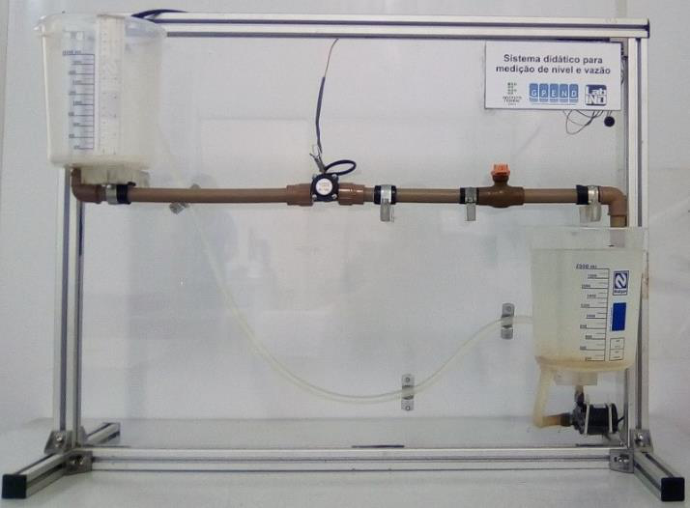

A bomba devolve água ao reservatório de sucção. Aumentar seu comando aumenta a vazão de retorno **e** o nível. Por isso, nível baixo pede um comando maior; neste caso, usamos **MAX**, não MIN.

Vamos trabalhar com variações em torno de uma condição inicial.

## Os modelos

\[
G_h(s)=\frac{0{,}1693}{54{,}813s+1},\qquad
G_q(s)=\frac{0{,}0252e^{-4{,}024s}}{49{,}756s+1}.
\]

O tempo está em segundos; as saídas são cm e L/min. A entrada é uma unidade de comando PWM, cuja escala absoluta não foi informada. Os modelos são locais; condições iniciais e limites de comando são didáticos.

In [3]:
modelos = {
    "nivel": {"ganho": 0.1693, "tempo": 54.813, "atraso": 0.0},
    "vazao": {"ganho": 0.0252, "tempo": 49.756, "atraso": 4.024},
}
nivel_inicial, vazao_inicial = 8.6, 2.45
limite_comando = 40.0  # Variação de PWM; não é uma porcentagem da bomba.

## Identificar com ruído

Aqui os dados são **simulados**, não medições da bancada. Primeiro ajusto ganho e constante de tempo com um ensaio. Depois testo o modelo em **outro ensaio**, sem ajustar novamente. O atraso permanece no valor publicado.

Troque o ruído: passar pelos pontos não basta.

In [4]:
def resposta_modelo(tempo, entrada, ganho, constante, atraso):
    passo = tempo[1] - tempo[0]
    entrada_atrasada = np.interp(tempo - atraso, tempo, entrada, left=0)
    fator = np.exp(-passo / constante)
    saida = np.zeros_like(tempo)
    for indice in range(len(tempo) - 1):
        saida[indice + 1] = (fator * saida[indice]
                            + (1 - fator) * ganho * entrada_atrasada[indice])
    return saida

tempo_ensaio = np.arange(0, 400.5, 0.5)
entrada_ajuste = np.where((tempo_ensaio >= 30) & (tempo_ensaio < 240), 12., 0.)
entrada_validacao = np.select(
    [tempo_ensaio < 30, tempo_ensaio < 130, tempo_ensaio < 260],
    [0., -8., 10.], default=4.)

In [5]:
intensidade_ruido = 1.0  # Posso mudar e executar a identificação novamente.
desvios_ruido = {"nivel": 0.04, "vazao": 0.01}
gerador = np.random.default_rng(42)
ensaios, identificados = {}, {}
for variavel, modelo in modelos.items():
    parametros = (modelo["ganho"], modelo["tempo"], modelo["atraso"])
    limpo = resposta_modelo(tempo_ensaio, entrada_ajuste, *parametros)
    medido = limpo + gerador.normal(0, desvios_ruido[variavel]
                                   * intensidade_ruido, len(limpo))
    def residuos(parametros):
        previsto = resposta_modelo(tempo_ensaio, entrada_ajuste,
                                   *parametros, modelo["atraso"])
        return previsto - medido
    ajuste = least_squares(residuos, [modelo["ganho"] * .8, modelo["tempo"] * 1.2],
                           bounds=([1e-5, 1.], [1., 200.]))
    identificados[variavel] = {"ganho": ajuste.x[0], "tempo": ajuste.x[1],
                              "atraso": modelo["atraso"]}
    ensaios[variavel] = {"ajuste": medido}
    print(f"{variavel}: K={ajuste.x[0]:.5f}; τ={ajuste.x[1]:.2f} s")

nivel: K=0.16915; τ=54.67 s
vazao: K=0.02518; τ=49.58 s


## Validar em outro ensaio

A linha usa os parâmetros estimados. Os pontos vêm de outra entrada e de novo ruído. O RMSE resume a diferença; compare sua unidade e o ruído.

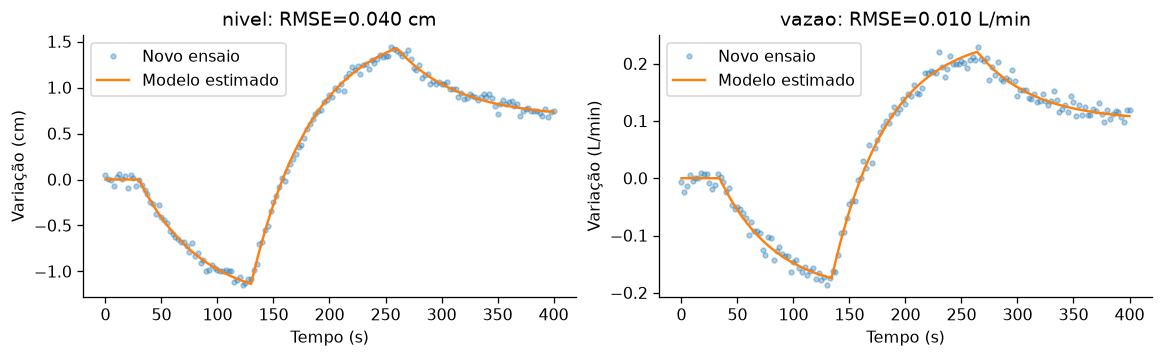

In [6]:
figura, eixos = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
erros_validacao = {}
for eixo, (variavel, modelo) in zip(eixos, modelos.items()):
    limpo = resposta_modelo(tempo_ensaio, entrada_validacao, *modelo.values())
    medido = limpo + gerador.normal(0, desvios_ruido[variavel]
                                   * intensidade_ruido, len(limpo))
    previsto = resposta_modelo(tempo_ensaio, entrada_validacao,
                               *identificados[variavel].values())
    ensaios[variavel]["validacao"] = medido
    erros_validacao[variavel] = np.sqrt(np.mean((medido - previsto)**2))
    eixo.plot(tempo_ensaio[::5], medido[::5], ".", alpha=.35, label="Novo ensaio")
    eixo.plot(tempo_ensaio, previsto, label="Modelo estimado")
    unidade = "cm" if variavel == "nivel" else "L/min"
    eixo.set(title=f"{variavel}: RMSE={erros_validacao[variavel]:.3f} {unidade}",
             xlabel="Tempo (s)", ylabel=f"Variação ({unidade})")
    eixo.legend()
plt.show()

## Sintonia IMC

Uso os modelos **estimados** para calcular os dois PI. Escolho \(\lambda=\tau\), uma sintonia conservadora. Aumentar \(\lambda\) deixa a ação mais lenta.

\[
K_c=\frac{2\tau+\theta}{2K\lambda},\qquad T_i=\tau+\frac{\theta}{2}.
\]

In [7]:
def sintonia_imc(modelo):
    ganho, constante, atraso = modelo.values()
    tempo_desejado = constante
    return {"proporcional": (2 * constante + atraso) / (2 * ganho * tempo_desejado),
            "integral": constante + atraso / 2,
            "rastreamento": tempo_desejado}

controladores = {nome: sintonia_imc(modelo) for nome, modelo in identificados.items()}
for nome, parametros in controladores.items():
    print(f"PI de {nome}: Kc={parametros['proporcional']:.3f}; "
          f"Ti={parametros['integral']:.2f} s")

PI de nivel: Kc=5.912; Ti=54.67 s
PI de vazao: Kc=41.326; Ti=51.60 s


## A decisão principal

Os PI calculam dois comandos para **a mesma bomba**. Se o nível pedir mais comando, ele assume. A vazão pode então se afastar da referência. Esse é o diferencial desta estratégia: **priorizar uma restrição**, em vez de atender simultaneamente a objetivos incompatíveis.

In [8]:
def selecionar_comando(comando_vazao, comando_nivel):
    return max(comando_vazao, comando_nivel)

comando_vazao, comando_nivel = -30., -21.
print("Só vazão:", comando_vazao)
print("Com seletor MAX:", selecionar_comando(comando_vazao, comando_nivel))

Só vazão: -30.0
Com seletor MAX: -21.0


## A simulação

Os modelos publicados representam a planta; os estimados sintonizam os PI. O controlador não selecionado acompanha o comando aplicado, evitando acumular integral sem atuar.

Reduzimos a referência de vazão após 400 s. As curvas mostram as respostas do modelo; o ruído entra nas medições usadas pelos PI.

In [9]:
def simular(vazao_final=1.8, nivel_minimo=5., ruido=1., seletor=True, passo=.5):
    tempo = np.arange(0, 1000 + passo / 2, passo)
    quantidade = len(tempo)
    nivel, vazao, comando = (np.zeros(quantidade) for _ in range(3))
    candidatos = np.zeros((quantidade, 2))
    nivel_selecionado = np.zeros(quantidade, dtype=bool)
    referencia = np.where(tempo < 400, 2.6, vazao_final)
    integrais = {"nivel": 0., "vazao": 0.}
    gerador = np.random.default_rng(7)
    ruido_nivel = gerador.normal(0, .04 * ruido, quantidade)
    ruido_vazao = gerador.normal(0, .01 * ruido, quantidade)
    for indice in range(quantidade - 1):
        erros = {"nivel": nivel_minimo - nivel_inicial - nivel[indice] - ruido_nivel[indice],
                 "vazao": referencia[indice] - vazao_inicial - vazao[indice] - ruido_vazao[indice]}
        propostas = {nome: controladores[nome]["proporcional"] * erros[nome]
                     + integrais[nome] for nome in integrais}
        candidatos[indice] = [propostas["vazao"], propostas["nivel"]]
        escolhido = (selecionar_comando(*candidatos[indice]) if seletor
                     else propostas["vazao"])
        comando[indice] = np.clip(escolhido, -limite_comando, limite_comando)
        nivel_selecionado[indice] = seletor and propostas["nivel"] > propostas["vazao"]
        for nome in integrais:
            parametros = controladores[nome]
            integrais[nome] += passo * (
                parametros["proporcional"] * erros[nome] / parametros["integral"]
                + (comando[indice] - propostas[nome]) / parametros["rastreamento"])
        # Cada passo atualiza uma função de transferência de primeira ordem.
        for nome, saida in [("nivel", nivel), ("vazao", vazao)]:
            modelo = modelos[nome]
            entrada = np.interp(tempo[indice] - modelo["atraso"], tempo[:indice + 1],
                                comando[:indice + 1], left=0.)
            fator = np.exp(-passo / modelo["tempo"])
            saida[indice + 1] = fator * saida[indice] + (1 - fator) * modelo["ganho"] * entrada
    comando[-1], candidatos[-1] = comando[-2], candidatos[-2]
    nivel_selecionado[-1] = nivel_selecionado[-2]
    return {"tempo": tempo, "nivel": nivel + nivel_inicial,
            "vazao": vazao + vazao_inicial, "comando": comando,
            "candidatos": candidatos, "nivel_selecionado": nivel_selecionado,
            "referencia": referencia}

In [10]:
def painel(vazao_final=1.8, nivel_minimo=5., ruido=1.):
    simples = simular(vazao_final, nivel_minimo, ruido, seletor=False)
    seletivo = simular(vazao_final, nivel_minimo, ruido, seletor=True)
    tempo = seletivo["tempo"]
    figura, eixos = plt.subplots(2, 1, figsize=(9, 5), sharex=True, layout="constrained")
    for eixo, variavel, unidade in zip(eixos, ["nivel", "vazao"], ["cm", "L/min"]):
        eixo.plot(tempo, simples[variavel], label="Só vazão", color="#3975c5")
        eixo.plot(tempo, seletivo[variavel], label="Seletor MAX", color="#16806a")
        eixo.set(ylabel=f"{variavel.capitalize()} ({unidade})")
        eixo.grid(alpha=.2)
    eixos[0].axhline(nivel_minimo, color="#c34f35", linestyle="--", label="Limite de nível")
    eixos[1].plot(tempo, seletivo["referencia"], "k--", label="Referência de vazão")
    eixos[1].plot(tempo, np.where(seletivo["nivel_selecionado"], seletivo["vazao"], np.nan),
                  color="#d78929", linewidth=3, label="Nível assumiu")
    for eixo in eixos:
        eixo.legend(loc="best", ncol=2, fontsize=9)
    eixos[1].set(xlabel="Tempo (s)")
    plt.show()
    print(f"Final com MAX: nível {seletivo['nivel'][-1]:.2f} cm; "
          f"vazão {seletivo['vazao'][-1]:.2f} L/min. Observe o trecho laranja.")

widgets.interact(painel,
    vazao_final=widgets.FloatSlider(value=1.8, min=1.6, max=2.5, step=.1,
                                   description="Vazão final", continuous_update=False),
    nivel_minimo=widgets.FloatSlider(value=5., min=4.5, max=7., step=.5,
                                    description="Nível mínimo", continuous_update=False),
    ruido=widgets.FloatSlider(value=1., min=0., max=3., step=.5,
                              description="Ruído ×", continuous_update=False));

interactive(children=(FloatSlider(value=1.8, continuous_update=False, description='Vazão final', max=2.5, min=…

## Experimente

1. Use vazão final **2,5 L/min**: os objetivos deixam de competir.
2. Volte para **1,8 L/min**: observe quem assume e o erro de vazão aceito.
3. Aumente o nível mínimo; depois, o ruído. A seleção muda?

O limite é um objetivo de controle, não uma barreira garantida. Ruído e dinâmica podem causar pequenas passagens temporárias.

## Referências

SILVA, G. R. S.; JESUS, L. F. F. S. [Avaliação de estratégia de controle override em um módulo didático de vazão e nível](https://www.confea.org.br/midias/uploads-imce/Contecc2019/Experi%C3%AAncia%20Profissional/AVALIA%C3%87%C3%83O%20DE%20ESTRATEGIA%20DE%20CONTROLE%20OVERRIDE%20EM%20UM%20MODULO%20DIDATICO%20DE%20VAZ%C3%83O%20E%20NIVEL.pdf). CONTECC, 2019. Modelos: Tabela 2; sintonia IMC: Tabela 1; fotografia: Figura 2, recortada.